<a href="https://colab.research.google.com/github/Andrian0s/ML4NLP1-2026-Tutorial-Notebooks/blob/main/lectures_supplementary_code_samples/l09_contextualized_embeddings_companion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# L09 Companion: Contextual Representations and Text Embeddings

This notebook accompanies the L09 deck *Contextual Representations and Text Embeddings*. You compute contextual similarities, candidate probabilities, and retrieval rankings, then test text queries against real images and speech. Each N-numbered section names the lecture frames it replays:

N1. **Contextual Token Occurrences vs. Static Types:** Tracking word vectors across layers; how context separates polysemous senses.
N2. **Masked Language Modeling (MLM):** The corruption mechanism, prediction heads, co-occurrence learning, and syntactic agreement.
N3. **From Tokens to Texts: Fine-Tuned Embeddings vs. Naive Pooling:** Compare raw pooling with a contrastively trained text encoder, and inspect the limitations of the comparison.
N4. **The InfoNCE Objective and Temperature:** In-batch negative matrix math, temperature scaling $\tau$, per-row losses, and independent matrix practice.
N5. **Retrieval in Practice: Bi-Encoder, Lexical Traps, and Cross-Encoder Reranking:** Exact dense vector search vs. TF-IDF lexical search and cross-encoder rescoring.
N6. **Modern Horizons: Matryoshka Representation Learning & Late Interaction:** Truncating dimension prefixes with a Matryoshka-trained model, and the MaxSim operator on raw BERT vectors (not a trained ColBERT model).
N7. **Cross-Modal Retrieval with EmbeddingGemma 2:** Encode real text, images, and synthesized speech with one pretrained multimodal model; inspect retrieval and reduced dimensions.

The notebook supports conceptual understanding through concrete code experiments; it is not a graded assignment.

Time estimates exclude installation and model downloads.

- **Core (approx. 50–60 minutes):** Parts 1, 2, 3, and 4.
- **Explore (optional, approx. 35–45 minutes):** Parts 5, 6, and 7.

**Learning goals:** Distinguish a token occurrence from a text vector; explain how objectives shape similarity; trace retrieval through encoders and score computations; test whether representations from different modalities are comparable.

**How to work:** Predict before running, inspect the output, then change one input or setting. **Your Turn** cells include a TODO scaffold; runnable checks and collapsed solutions support comparison afterward.

**Runtime:** Run setup, then Parts 1–6 in order; Part 6 reuses the corpus from Part 5. Part 7 only needs setup and can be run independently. CPU is supported; a CUDA GPU is used when available; downloads for all models total several GB. Part 7 loads the largest model and benefits from a Colab GPU. Speech is generated on the fly with Google TTS; the two example words are sent to that service. Colab prepares a separate TTS helper automatically. Local Jupyter setup instructions appear in N7. WAV conversion uses soundfile and librosa, without FFmpeg. Restart the runtime and rerun setup if an already-imported library was upgraded. All encoders are used for inference: no model parameters are updated.

In [1]:
# Dependencies: Python, PyTorch, Transformers, Sentence Transformers, NumPy,
# scikit-learn, Pillow, requests, librosa, soundfile. Only Colab installs here.
# Explicit audio dependencies avoid unused speech-decoder packages that pin NumPy 1.x.
import sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    %pip install -q "transformers @ git+https://github.com/huggingface/transformers.git@e4e4e98845fcf92e2b75f709f356fbc838b55d11" "sentence-transformers[image]==6.2.0" scikit-learn torch "numpy>=2,<3" pillow requests librosa soundfile
# Else: provision those dependencies in your own environment before running.

import importlib.metadata
import numpy as np
import torch
import torch.nn.functional as F
from IPython.display import display

np.set_printoptions(precision=3, suppress=True)
torch.set_printoptions(precision=3, sci_mode=False)
np.random.seed(42)
torch.manual_seed(42)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE}")
for package in ("torch", "transformers", "sentence-transformers"):
    print(f"{package}: {importlib.metadata.version(package)}")

Device: cpu
torch: 2.15.0
transformers: 5.23.0.dev0
sentence-transformers: 6.2.0


## N1. Contextual Token Occurrences vs. Static Types

**A token occurrence receives a representation that depends on its context.**

Replays: *Ambiguous Tokens Need Context; BERT Contextualization in Action*.

In static word embeddings (such as word2vec or GloVe), each vocabulary type receives a single fixed vector $\mathbf{w} \in \mathbb{R}^d$. A polysemous word (e.g. *bank*) is forced into a static compromise vector regardless of whether it refers to a river edge or a financial institution.

In a contextual encoder (like BERT), the representation is a function of the entire sequence:
$$\mathbf{h}_i = f_{\theta}(w_1, \dots, w_n)_i$$

Let us track the occurrence representation of the token **"bank"** across three sentences:
1. River 1: *"The river bank was muddy and overflowing after heavy rain."*
2. River 2: *"We sat on the grassy bank watching boats pass along the water."*
3. Finance: *"He walked into the bank to deposit cash into his account."*

**Predict:** At layer 0, will the same token have identical vectors at different positions? In later layers, which pair should be more similar: river–river or river–finance? Write your prediction before running.

In [2]:
from transformers import BertTokenizer, BertModel

# Load standard bert-base-uncased with all intermediate hidden states enabled
tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")
model = BertModel.from_pretrained("bert-base-uncased", output_hidden_states=True)
model.to(DEVICE).eval()

sent_river = "The river bank was muddy and overflowing after heavy rain."
sent_river2 = "We sat on the grassy bank watching boats pass along the water."
sent_money = "He walked into the bank to deposit cash into his account."

inputs_river = tokenizer(sent_river, return_tensors="pt").to(DEVICE)
inputs_river2 = tokenizer(sent_river2, return_tensors="pt").to(DEVICE)
inputs_money = tokenizer(sent_money, return_tensors="pt").to(DEVICE)

with torch.no_grad():
    out_river = model(**inputs_river)
    out_river2 = model(**inputs_river2)
    out_money = model(**inputs_money)

# Locate token position for 'bank' in each sentence
id_bank = tokenizer.convert_tokens_to_ids("bank")
idx_river = (inputs_river.input_ids[0] == id_bank).nonzero().item()
idx_river2 = (inputs_river2.input_ids[0] == id_bank).nonzero().item()
idx_money = (inputs_money.input_ids[0] == id_bank).nonzero().item()

num_layers = len(out_river.hidden_states)  # 13: Layer 0 (input embeddings) + 12 transformer layers
print(f"Total layers available (0 to 12): {num_layers}")

/private/tmp/l09-check-venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1111 11:04:24.324000 26867 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 19340.68it/s]


[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Total layers available (0 to 12): 13


In [3]:
# Track cosine similarities layer by layer with widened column formatting
print(f"{'Layer':<12}{'Cosine Sim (River vs. Finance)':<35}{'Cosine Sim (River 1 vs. River 2)':<35}")
print("-" * 82)

for layer in range(num_layers):
    v_riv = out_river.hidden_states[layer][0, idx_river]
    v_riv2 = out_river2.hidden_states[layer][0, idx_river2]
    v_mon = out_money.hidden_states[layer][0, idx_money]

    sim_diff_sense = F.cosine_similarity(v_riv, v_mon, dim=0).item()
    sim_same_sense = F.cosine_similarity(v_riv, v_riv2, dim=0).item()

    layer_name = "L0 (Input)" if layer == 0 else f"Layer {layer}"
    print(f"{layer_name:<12}{sim_diff_sense:<35.4f}{sim_same_sense:<35.4f}")

Layer       Cosine Sim (River vs. Finance)     Cosine Sim (River 1 vs. River 2)   
----------------------------------------------------------------------------------
L0 (Input)  0.9546                             0.9502                             
Layer 1     0.6830                             0.8509                             
Layer 2     0.5959                             0.8429                             
Layer 3     0.5710                             0.8094                             
Layer 4     0.5203                             0.7708                             
Layer 5     0.4867                             0.7551                             
Layer 6     0.4922                             0.7261                             
Layer 7     0.4681                             0.7253                             
Layer 8     0.4685                             0.7259                             
Layer 9     0.4252                             0.6938                             
Laye

### Read the result

Compare the two similarity columns across layers. Is the same-sense pair always more similar? Where is the gap largest?

Layer 0 includes **token, position, and token-type embeddings, followed by LayerNorm**. With evaluation mode enabled, context has not yet mixed across positions. Different positions can therefore give different vectors even for the same token. The later layers incorporate context, but similarity need not change monotonically or cleanly isolate word sense.

These three sentences illustrate contextual dependence; they are not a word-sense benchmark. Sentence topic, position, and syntax also change.

### Your Turn: Change One Factor

Before running the next cell, predict how the similarity of *record* will change between input and final layers. Then move the word to the same position in both sentences and rerun. Which confound does that control? Can two examples establish that a layer encodes grammatical categories?

In [4]:
# Worked experiment: run, then edit the sentences to test your prediction
sent_noun = "He broke the world record in the 100 meter sprint."
sent_verb = "Please record this lecture so students can watch later."

inputs_noun = tokenizer(sent_noun, return_tensors="pt").to(DEVICE)
inputs_verb = tokenizer(sent_verb, return_tensors="pt").to(DEVICE)

# Locate token position for 'record'
id_record = tokenizer.convert_tokens_to_ids("record")
idx_noun = (inputs_noun.input_ids[0] == id_record).nonzero().item()
idx_verb = (inputs_verb.input_ids[0] == id_record).nonzero().item()

with torch.no_grad():
    out_noun = model(**inputs_noun)
    out_verb = model(**inputs_verb)

sim_l0 = F.cosine_similarity(out_noun.hidden_states[0][0, idx_noun], out_verb.hidden_states[0][0, idx_verb], dim=0).item()
sim_l12 = F.cosine_similarity(out_noun.hidden_states[12][0, idx_noun], out_verb.hidden_states[12][0, idx_verb], dim=0).item()
print(f"'record' similarity at Layer 0 (Input):      {sim_l0:.4f}")
print(f"'record' similarity at Layer 12 (Contextual): {sim_l12:.4f}")

'record' similarity at Layer 0 (Input):      0.9480
'record' similarity at Layer 12 (Contextual): 0.2735


**Check yourself.**

1. Why can the same token change its representation without any learning?
2. Why is the bank comparison not a controlled word-sense benchmark?

<details>
<summary>Solution: Context and fixed parameters</summary>

1. The fixed encoder computes a new activation from each input context; inference changes activations, not weights.

2. Position, syntax, topic, and sentence length also differ. Matching positions removes only one confound.
</details>

## N2. Masked Language Modeling and Heads

**The MLM head predicts vocabulary tokens from contextual representations.**

Replays: *Why BERT Masks Input Tokens; Masked Language Modeling; Your Turn: Context from Both Sides*.

In BERT's Masked Language Model objective:
1. 15% of token positions are selected for prediction.
2. Of those selected:
   - **80%** are replaced by `[MASK]`
   - **10%** are replaced by a random token
   - **10%** are kept unchanged

### The Prediction Head Architecture
For hidden vector $\mathbf{h}_i \in \mathbb{R}^d$ at position $i$, the actual prediction head in BERT is not just a single matrix multiplication. It applies:
1. A dense intermediate projection: $\mathbf{z}_i = \text{GELU}(\mathbf{W}_{\text{dense}} \mathbf{h}_i + \mathbf{b}_{\text{dense}})$
2. Layer normalization: $\mathbf{z}_i' = \text{LayerNorm}(\mathbf{z}_i)$
3. An affine projection to vocabulary size $V$, tied to the input embedding matrix $\mathbf{E} \in \mathbb{R}^{V \times d}$ plus an output bias $\mathbf{b}_{\text{out}}$:
$$P(w \mid \mathbf{h}_i) = \text{softmax}(\mathbf{E} \mathbf{z}_i' + \mathbf{b}_{\text{out}})$$

Inputs:
- “The capital of Switzerland is [MASK].”
- “The [MASK] on the bottles have faded.”

**Predict:** Write one completion for each mask and identify constraining words on both sides. Must a fluent completion be factually correct?

We run inference with manually inserted masks. We do not implement the 80/10/10 training corruption or update any weights. For multiple masks, the helper reports each position from one forward pass; it does not generate a jointly decoded completion.

In [5]:
from transformers import BertForMaskedLM

mlm_model = BertForMaskedLM.from_pretrained("bert-base-uncased")
mlm_model.to(DEVICE).eval()

def inspect_mask_predictions(text, top_k=5):
    inputs = tokenizer(text, return_tensors="pt").to(DEVICE)
    mask_token_id = tokenizer.mask_token_id
    mask_indices = (inputs.input_ids[0] == mask_token_id).nonzero(as_tuple=True)[0]

    if len(mask_indices) == 0:
        print("No [MASK] token found in input text!")
        return

    with torch.no_grad():
        outputs = mlm_model(**inputs)
        logits = outputs.logits

    for m_idx in mask_indices:
        pos = m_idx.item()
        probs = F.softmax(logits[0, pos], dim=-1)
        top_probs, top_ids = torch.topk(probs, top_k)
        print(f"\nPredictions for position {pos} in: \"{text}\"")
        for rank, (prob, tok_id) in enumerate(zip(top_probs, top_ids), 1):
            word = tokenizer.decode([tok_id.item()]).strip()
            print(f"  {rank}. {word:<15} (p = {prob.item():.4f})")

# Example 1: Geographic co-occurrence vs. factual knowledge
inspect_mask_predictions("The capital of Switzerland is [MASK].", top_k=5)

# Example 2: Context from both sides (from the lecture's bottle example)
inspect_mask_predictions("The [MASK] on the bottles have faded.", top_k=5)

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 202/202 [00:00<00:00, 20232.34it/s]


[transformers] BertForMaskedLM LOAD REPORT from: bert-base-uncased
Key                         | Status     |  | 
----------------------------+------------+--+-
bert.pooler.dense.bias      | UNEXPECTED |  | 
bert.pooler.dense.weight    | UNEXPECTED |  | 
cls.seq_relationship.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Predictions for position 6 in: "The capital of Switzerland is [MASK]."
  1. geneva          (p = 0.6191)
  2. zurich          (p = 0.1064)
  3. bern            (p = 0.0983)
  4. basel           (p = 0.0906)
  5. lausanne        (p = 0.0717)

Predictions for position 2 in: "The [MASK] on the bottles have faded."
  1. labels          (p = 0.1076)
  2. lights          (p = 0.0704)
  3. marks           (p = 0.0500)
  4. markings        (p = 0.0389)
  5. pictures        (p = 0.0378)


### Interpret Predictions as Model Outputs

Read your own top-five lists rather than expecting fixed tokens or probabilities. A plausible completion is not a verified fact, and its softmax probability is not a calibrated probability that a factual claim is true. Original BERT was pretrained on BooksCorpus and English Wikipedia.

For the bottles example, identify evidence from **both sides** of the mask. Several completions can be plausible; one mask predicts one WordPiece token.

### Your Turn: Agreement Across a Distractor

Predict whether singular or plural verb forms receive more probability:

- *The key to the cabinets [MASK] on the table.*
- *The keys to the cabinet [MASK] on the table.*

Run the next cell, then remove the intervening phrase. The displayed sums cover four selected verbs, not all grammatical completions. Successful predictions are behavioral evidence; they do not reveal which attention head caused the result.

In [6]:
sentences_agreement = [
    "The key to the cabinets [MASK] on the table.",
    "The keys to the cabinet [MASK] on the table."
]

for s in sentences_agreement:
    inputs = tokenizer(s, return_tensors="pt").to(DEVICE)
    mask_pos = (inputs.input_ids[0] == tokenizer.mask_token_id).nonzero().item()
    with torch.no_grad():
        probs = F.softmax(mlm_model(**inputs).logits[0, mask_pos], dim=-1)

    id_is = tokenizer.convert_tokens_to_ids("is")
    id_are = tokenizer.convert_tokens_to_ids("are")
    id_was = tokenizer.convert_tokens_to_ids("was")
    id_were = tokenizer.convert_tokens_to_ids("were")

    p_sing = probs[id_is].item() + probs[id_was].item()
    p_plur = probs[id_are].item() + probs[id_were].item()

    print(f"Sentence: \"{s}\"")
    print(f"  P(is/was)   = {p_sing:.4f}  (Singular)")
    print(f"  P(are/were) = {p_plur:.4f}  (Plural)\n")

Sentence: "The key to the cabinets [MASK] on the table."
  P(is/was)   = 0.4427  (Singular)
  P(are/were) = 0.0022  (Plural)

Sentence: "The keys to the cabinet [MASK] on the table."
  P(is/was)   = 0.0024  (Singular)
  P(are/were) = 0.5804  (Plural)



**Check yourself.**

1. Why insert a mask when probing BERT?
2. Does correct agreement reveal a particular attention head's role?
3. Why can a fluent predicted capital still be wrong?

<details>
<summary>Solution: MLM predictions and evidence</summary>

1. It removes the token identity at the position being predicted; otherwise copying that identity is an available shortcut.

2. No. It is a behavioral result of the whole network, not a causal explanation of an attention head.

3. The vocabulary distribution models compatibility with context; its probabilities are not calibrated factual truth probabilities.
</details>

## N3. From Tokens to Texts

**Pooling produces a text vector, while training determines which comparisons are useful.**

Replays: *Comparing Pooled Sentence Representations; Pooling Needs a Suitable Training Objective*.

A fundamental finding discussed in the lecture (Reimers & Gurevych, 2019) is that **BERT was pretrained with MLM and next-sentence prediction, not a sentence-level cosine-similarity objective**.

Mean pooling turns token vectors into one text vector, but it does not itself train a useful similarity metric. Raw BERT representations can show a high common cosine baseline (**anisotropy**); the extent depends on layer, pooling, and data.

We compare raw BERT with `all-MiniLM-L6-v2`, a model trained contrastively on a large sentence-pair collection. This compares two complete pretrained systems: architecture, data, and objective all differ. It does not isolate the effect of fine-tuning alone.

Compare these pairs:
- “A dog is chasing a ball in the grass.” / “A canine plays with a tennis ball on the lawn.”
- “A man is playing a violin on stage.” / “A musician performs an acoustic instrument for a crowd.”
- “The stock market experienced heavy trading volatility today.” / “The recipe calls for two cups of organic whole wheat flour.”

**Predict:** Which pair should rank highest? The examples are approximate semantic relationships, not gold entailment labels. The first pair also differs in details (chasing versus playing).

In [7]:
from sentence_transformers import SentenceTransformer

embedder = SentenceTransformer("all-MiniLM-L6-v2", device=DEVICE)
embedder.eval()

test_pairs = [
    ("A dog is chasing a ball in the grass.", "A canine plays with a tennis ball on the lawn.", "Close meaning / changed details"),
    ("A man is playing a violin on stage.", "A musician performs an acoustic instrument for a crowd.", "Related event / changed details"),
    ("The stock market experienced heavy trading volatility today.", "The recipe calls for two cups of organic whole wheat flour.", "Completely Unrelated")
]

def get_raw_bert_mean_pooling(text):
    # Accept one text or a list; padding is excluded, special tokens are included.
    inputs = tokenizer(text, return_tensors="pt", padding=True, truncation=True,
                       max_length=512).to(DEVICE)
    with torch.inference_mode():
        token_embeddings = model(**inputs, output_hidden_states=False).last_hidden_state
    mask = inputs.attention_mask.unsqueeze(-1).to(token_embeddings.dtype)
    return (token_embeddings * mask).sum(1) / mask.sum(1).clamp_min(1)

print(f"{'Pair Type':<32}{'Raw BERT (Mean)':<18}{'Fine-Tuned Embedder':<20}")
print("-" * 70)

for s1, s2, desc in test_pairs:
    # Raw BERT cosine similarity
    e1_raw = get_raw_bert_mean_pooling(s1)
    e2_raw = get_raw_bert_mean_pooling(s2)
    sim_raw = F.cosine_similarity(e1_raw, e2_raw).item()

    # Fine-tuned embedder cosine similarity
    e1_ft = embedder.encode(s1, convert_to_tensor=True)
    e2_ft = embedder.encode(s2, convert_to_tensor=True)
    sim_ft = F.cosine_similarity(e1_ft.unsqueeze(0), e2_ft.unsqueeze(0)).item()

    print(f"{desc:<32}{sim_raw:<18.4f}{sim_ft:<20.4f}")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 19614.68it/s]

Pair Type                       Raw BERT (Mean)   Fine-Tuned Embedder 
----------------------------------------------------------------------
Close meaning / changed details 0.9252            0.6574              
Related event / changed details 0.8671            0.4388              
Completely Unrelated            0.4182            -0.0354             


### Compare Rankings and Baselines

Read the table: does each model rank the pairs as you predicted? How large are the gaps? Scores from different models are not calibrated to a common scale, and cosine is not a probability.

### Your Turn: Unrelated-Sentence Baseline

The next cell encodes each sentence once, then computes all 15 distinct pairs. Predict which model will have the higher mean cosine. Run it, then replace the sentences with a different domain. Six hand-selected sentences illustrate a baseline; they do not establish a general quality ranking or prove anisotropy on their own.

In [8]:
# Starter scaffold: 6 mutually unrelated sentences
unrelated_sentences = [
    "The solar eclipse cast a dark shadow across the northern continent.",
    "The bakery on the corner sells fresh sourdough bread every morning.",
    "Python uses indentation rather than braces to define code blocks.",
    "The archaeological team excavated Roman coins dating to the second century.",
    "Photosynthesis converts light energy into chemical energy in green plants.",
    "The Federal Reserve adjusted short-term interest rates by twenty-five basis points."
]

# Encode once per model, then compare all distinct pairs.
raw_vectors = F.normalize(get_raw_bert_mean_pooling(unrelated_sentences), dim=-1)
ft_vectors = embedder.encode(unrelated_sentences, convert_to_tensor=True,
                             normalize_embeddings=True)
rows, cols = torch.triu_indices(len(unrelated_sentences), len(unrelated_sentences), offset=1, device=DEVICE)
raw_sims = (raw_vectors @ raw_vectors.T)[rows, cols].cpu().numpy()
ft_sims = (ft_vectors @ ft_vectors.T)[rows, cols].cpu().numpy()
for name, values in [("Raw BERT mean", raw_sims), ("Contrastive MiniLM", ft_sims)]:
    print(f"{name}: n={len(values)}, mean={values.mean():.4f}, "
          f"std={values.std():.4f}, min={values.min():.4f}, max={values.max():.4f}")

Raw BERT mean: n=15, mean=0.5108, std=0.0497, min=0.4352, max=0.6110
Contrastive MiniLM: n=15, mean=0.0231, std=0.0649, min=-0.1493, max=0.1384


**Check yourself.**

1. What does mean pooling specify, and what does it not specify?
2. Can this BERT–MiniLM experiment isolate the effect of the contrastive objective?

<details>
<summary>Solution: Pooling, geometry, and comparison</summary>

1. It specifies aggregation over token vectors. It does not train the encoder to make text-level cosine useful.

2. No. Architecture, data, and objective differ. It compares pretrained systems rather than a controlled ablation.
</details>

## N4. InfoNCE and Temperature

**InfoNCE treats each query as classification over a set of candidate passages.**

Replays: *Train Text Vectors for Retrieval; Reuse a Batch to Supply Negatives; Your Turn: Temperature and Hard Negatives; Practice: Candidate Probabilities*.

Many modern dual-encoder text representation models are trained on pairs $(q_i, p_i)$ using the **InfoNCE** (Information Noise-Contrastive Estimation) loss with **in-batch negatives**.

Given a batch of $B$ queries and $B$ corresponding positive documents:
- $q_i$ and $p_i$ are a positive pair (diagonal entries $S_{ii}$).
- For query $i$, all other documents $p_j$ ($j \neq i$) in the mini-batch are treated as negative examples (off-diagonal entries $S_{ij}$). Some may actually be relevant: these are false negatives.

Keep raw similarities and logits separate:
$$S_{ij}=s(q_i,p_j)=\frac{\mathbf q_i^\top\mathbf p_j}{\|\mathbf q_i\|\|\mathbf p_j\|},\qquad Z_{ij}=S_{ij}/\tau.$$

Each row is a classification problem with positive column $i$:
$$\ell_i=-\log\frac{\exp(Z_{ii})}{\sum_{j=1}^{B}\exp(Z_{ij})}=-\log P(p_i\mid q_i).$$

The query-to-document batch loss is the mean over the batch: $\mathcal{L} = \frac{1}{B} \sum_{i=1}^B \ell_i$ (optionally symmetrized with document-to-query cross-entropy).

### Replay the Slide: Two Candidates

The slide gives $s(q,p)=0.8$, $s(q,n)=0.7$ and $\tau\in\{1,0.01\}$.

**Predict:** Estimate the positive probability at each temperature. Does the top candidate change?

In [9]:
# Shape: one query × two candidate passages; column 0 is positive.
slide_scores = torch.tensor([[0.8, 0.7]], device=DEVICE)
for tau in (1.0, 0.01):
    slide_probs = F.softmax(slide_scores / tau, dim=1)
    print(f"tau={tau:g}: P(positive)={slide_probs[0, 0].item():.6f}")

tau=1: P(positive)=0.524979
tau=0.01: P(positive)=0.999955


Compare your estimates with the output. Explain why the candidate order and the probabilities behave differently.

<details>
<summary>Solution: Temperature changes sharpness for the fixed score gap</summary>

The positive probabilities are about 0.524979 and 0.999955. Both temperatures preserve the winner. The gap in logits changes from 0.1 to 10; no encoder parameters were updated.
</details>

### Extend to a Batch

In [10]:
def infonce_loss_from_scores(sim_matrix, temperature=0.2, symmetric=False):
    """
    Computes InfoNCE loss from a precomputed cosine similarity matrix (B, B).
    Returns (mean_loss, per_row_losses, scaled_logits, softmax_probs).
    Rows and probabilities are query-to-document even when mean_loss is symmetric.
    """
    if not np.isfinite(temperature) or temperature <= 0:
        raise ValueError("temperature must be finite and positive")
    if sim_matrix.ndim != 2 or sim_matrix.shape[0] != sim_matrix.shape[1] or sim_matrix.shape[0] == 0:
        raise ValueError("Expected a nonempty square query-document matrix")
    if not torch.isfinite(sim_matrix).all():
        raise ValueError("Scores must be finite")
    scaled_logits = sim_matrix / temperature
    batch_size = sim_matrix.size(0)
    labels = torch.arange(batch_size, device=sim_matrix.device)

    # Per-row query-to-document cross-entropy loss
    per_row_losses = F.cross_entropy(scaled_logits, labels, reduction="none")
    loss = per_row_losses.mean()

    if symmetric:
        loss_d2q = F.cross_entropy(scaled_logits.T, labels)
        loss = (loss + loss_d2q) / 2

    probs = F.softmax(scaled_logits, dim=-1)
    return loss, per_row_losses, scaled_logits, probs

### Predict the Effect of Temperature

The following $4 \times 4$ matrix contains **invented cosine scores**, with diagonal positives. No encoder is trained here.

Before running: will reducing positive temperature change the winning candidate, its probability, or both? Inspect row 0 before comparing the batch mean.

In [11]:
# Simulated batch of 4 queries and 4 documents
# Row 0: True positive has cosine sim 0.85, hard negative has 0.70, others 0.30, 0.10
batch_scores = torch.tensor([
    [0.85, 0.70, 0.30, 0.10],
    [0.40, 0.90, 0.50, 0.20],
    [0.15, 0.35, 0.80, 0.25],
    [0.20, 0.10, 0.40, 0.95]
], device=DEVICE)

temperatures = [1.0, 0.2, 0.05]

print("Row 0 (Query 0) behavior under different temperatures:")
print(f"{'Temperature':<14}{'P(Positive)':<14}{'P(Hard Neg)':<14}{'P(Neg 2)':<12}{'P(Neg 3)':<12}{'Row 0 Loss':<12}{'Batch Mean Loss':<16}")
print("-" * 86)

for tau in temperatures:
    loss, row_losses, logits, probs = infonce_loss_from_scores(batch_scores, temperature=tau)
    p0 = probs[0]
    print(f"tau = {tau:<8.2f}{p0[0].item():<14.4f}{p0[1].item():<14.4f}{p0[2].item():<12.4f}{p0[3].item():<12.4f}{row_losses[0].item():<12.4f}{loss.item():<16.4f}")

Row 0 (Query 0) behavior under different temperatures:
Temperature   P(Positive)   P(Hard Neg)   P(Neg 2)    P(Neg 3)    Row 0 Loss  Batch Mean Loss 
--------------------------------------------------------------------------------------
tau = 1.00    0.3436        0.2958        0.1983      0.1623      1.0682      1.0005          
tau = 0.20    0.6411        0.3028        0.0410      0.0151      0.4446      0.2379          
tau = 0.05    0.9526        0.0474        0.0000      0.0000      0.0486      0.0123          


### Compare Your Prediction

Which probabilities and losses changed? Did any winning candidate change?

<details>
<summary>Explanation: Temperature, score gradients, and false negatives</summary>


- Positive temperature rescales fixed scores without changing their ranking.
- Lower temperature sharpens the distribution. When the positive wins, loss tends toward zero; when a negative wins, loss grows as temperature approaches zero.
- For raw score $c_{ij}$, the row-loss derivative is $(p_{ij}-\mathbb{1}[j=i])/\tau$. Both probability saturation and the $1/\tau$ factor matter: lower temperature does not always mean a larger gradient.
- A false negative that receives high probability is still penalized by the diagonal-only target.

</details>

**Predict a counterexample:** Copy the matrix, set `[0, 1]` to `0.95`, and repeat the temperature sweep. Does row 0 loss rise or fall as temperature falls? Explain using the designated positive. What changes if document 1 is also relevant?

### Your Turn: After-Class Practice Matrix
The lecture slide *"Practice: Candidate Probabilities"* poses the following independent calculation problem:
$$S = \begin{pmatrix} 0.8 & 0.6 \\ 0.3 & 0.9 \end{pmatrix}, \qquad \tau = 0.2$$
Calculate row-wise probabilities and losses by hand first. Then run the worked verification below:

In [12]:
# Your Turn starter: the slide's raw similarity matrix, shape (2, 2).
S_practice = torch.tensor([[0.8, 0.6], [0.3, 0.9]], device=DEVICE)
tau_practice = 0.2
labels_practice = torch.arange(2, device=DEVICE)

# TODO: replace None with the scaled logits, row probabilities, and row losses.
logits_practice = None
probs_practice = None
loss_practice = None

if any(value is None for value in (logits_practice, probs_practice, loss_practice)):
    print("Complete the three TODO expressions, or compare with the collapsed solution.")
else:
    print("Your row probabilities:", probs_practice)
    print("Your row losses:", loss_practice)
    print("Your mean loss:", loss_practice.mean().item())

Complete the three TODO expressions, or compare with the collapsed solution.


<details>
<summary>Solution: Row-wise logits, probabilities, and losses</summary>

```python
logits_practice = S_practice / tau_practice
probs_practice = F.softmax(logits_practice, dim=1)
loss_practice = F.cross_entropy(logits_practice, labels_practice, reduction="none")
```

The positive probabilities are 0.7311 and 0.9526; mean loss is 0.1809. Each row normalizes over its own two candidates.
</details>

Run this independent numerical check after attempting the TODOs. It also checks the slide's two suggested invariants.

In [13]:
# Reference verification, separate from your starter variables.
Z_check = S_practice / tau_practice
P_check = torch.softmax(Z_check, dim=1)
ell_check = -torch.log_softmax(Z_check, dim=1).diagonal()
assert torch.allclose(P_check.sum(1), torch.ones(2, device=DEVICE))
assert torch.allclose(P_check, torch.softmax(Z_check - Z_check.max(1, keepdim=True).values, dim=1))
S_lower = S_practice.clone()
S_lower[0, 0] -= 0.1
ell_lower = F.cross_entropy(S_lower / tau_practice, labels_practice, reduction="none")
assert ell_lower[0] > ell_check[0]
print("Positive probabilities:", P_check.diagonal().cpu().tolist())
print("Row losses:", ell_check.cpu().tolist())
print(f"Mean loss: {ell_check.mean().item():.4f}; all invariants passed.")

Positive probabilities: [0.7310585975646973, 0.9525741338729858]
Row losses: [0.31326165795326233, 0.04858732968568802]
Mean loss: 0.1809; all invariants passed.


**Check yourself.**

1. How many designated negatives does a batch of 64 paired queries and passages give each query?
2. Why can low temperature hurt when a false negative wins?
3. Why must S and Z have separate names?

<details>
<summary>Solution: InfoNCE labels, logits, and false negatives</summary>

1. 63, assuming the other paired passages are treated as irrelevant. Some can actually be relevant.

2. The diagonal-only target penalizes probability on that useful passage. Sharpening a mistaken ordering can increase loss and harmful training pressure.

3. S stores raw cosine similarities; Z=S/tau stores logits. Softmax acts on Z, so temperature is applied exactly once.
</details>

## N5. Retrieve, Then Rerank · Deeper Investigation

**A bi-encoder retrieves candidates that a cross-encoder can rescore jointly.**

Replays: *Retrieve, Then Rerank; Cross-Encoders Are Accurate but Slow*.

A common retrieval pipeline separates two computations:

1. **Bi-encoder:** Embed documents offline; embed each incoming query online. Compare query and document vectors. Our six-document example uses exact search; large corpora often use approximate indexes.
2. **Cross-encoder:** Process each query–candidate pair jointly and rescore a small candidate set. This permits interaction across the texts but requires another model pass for every pair.

**Predict:** Which document answers each query? Where might exact word matching struggle? A reranker can only reorder retrieved candidates; it cannot recover a relevant document absent from its input.

All three models below remain fixed. Only the input and computed representations change.

In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity as tfidf_cos_sim
from sentence_transformers import CrossEncoder

corpus = [
    "Python is a high-level general-purpose programming language known for readability.",
    "The python snake is a non-venomous constrictor found in tropical regions of Africa and Asia.",
    "Machine learning models learn patterns directly from empirical training datasets.",
    "Gradient descent iteratively updates model parameters by moving along the negative loss gradient.",
    "A bank by the river collapsed after heavy floods washed away the embankment.",
    "Financial institutions like retail banks provide checking accounts and credit loans."
]

# 1. Lexical baseline: TF-IDF
tfidf_vec = TfidfVectorizer()
tfidf_corpus = tfidf_vec.fit_transform(corpus)

# 2. Dense baseline: Bi-encoder
doc_embeddings = embedder.encode(corpus, convert_to_tensor=True)
doc_embeddings = F.normalize(doc_embeddings, p=2, dim=-1)

# 3. Second-stage reranker: Cross-encoder
cross_encoder = CrossEncoder("cross-encoder/ms-marco-MiniLM-L-6-v2", device=DEVICE)

queries = [
    ("How do neural networks optimize their weights?", "Trap 1: Synonymy / Paraphrase (Zero keyword overlap with Doc 3)"),
    ("Is the python reptile venomous to humans?", "Trap 2: Lexical Ambiguity (Keyword 'python' shared with programming Doc 0)")
]

candidate_count = 2  # Your Turn: try 1, then len(corpus).

for q, trap_desc in queries:
    print(f"=== Query: \"{q}\" ===")
    print(f"{trap_desc}")

    # TF-IDF lexical scores
    q_tfidf = tfidf_vec.transform([q])
    scores_tfidf = tfidf_cos_sim(q_tfidf, tfidf_corpus)[0]
    if np.allclose(scores_tfidf, 0):
        print("  [Lexical TF-IDF] All documents tie at zero: no lexical evidence.")
    else:
        best_tfidf = np.argmax(scores_tfidf)
        print(f"  [Lexical TF-IDF] Top match: Doc {best_tfidf} (score = {scores_tfidf[best_tfidf]:.4f})")

    # Bi-encoder dense scores
    q_emb = embedder.encode(q, convert_to_tensor=True)
    q_emb = F.normalize(q_emb, p=2, dim=-1)
    scores_bi = torch.matmul(doc_embeddings, q_emb).cpu().numpy()
    best_bi = np.argmax(scores_bi)
    print(f"  [Dense Bi-Encoder] Top match: Doc {best_bi} (score = {scores_bi[best_bi]:.4f})")

    # Cross-encoder rescoring of top-2 bi-encoder candidates
    top2_indices = np.argsort(scores_bi)[-candidate_count:][::-1]
    pairs = [[q, corpus[idx]] for idx in top2_indices]
    ce_scores = cross_encoder.predict(pairs)
    for idx, score in zip(top2_indices, ce_scores):
        print(f"    Candidate Doc {idx}: reranker score={float(score):.4f} | {corpus[idx]}")
    best_ce = top2_indices[np.argmax(ce_scores)]
    print(f"  [Cross-Encoder Rerank] Rescored top candidates: Best = Doc {best_ce}\n")

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 15449.99it/s]

=== Query: "How do neural networks optimize their weights?" ===
Trap 1: Synonymy / Paraphrase (Zero keyword overlap with Doc 3)
  [Lexical TF-IDF] All documents tie at zero: no lexical evidence.
  [Dense Bi-Encoder] Top match: Doc 3 (score = 0.4124)
    Candidate Doc 3: reranker score=-11.3803 | Gradient descent iteratively updates model parameters by moving along the negative loss gradient.
    Candidate Doc 2: reranker score=-11.4212 | Machine learning models learn patterns directly from empirical training datasets.
  [Cross-Encoder Rerank] Rescored top candidates: Best = Doc 3

=== Query: "Is the python reptile venomous to humans?" ===
Trap 2: Lexical Ambiguity (Keyword 'python' shared with programming Doc 0)
  [Lexical TF-IDF] Top match: Doc 1 (score = 0.4574)
  [Dense Bi-Encoder] Top match: Doc 1 (score = 0.6790)
    Candidate Doc 1: reranker score=2.9858 | The python snake is a non-venomous constrictor found in tropical regions of Africa and Asia.
    Candidate Doc 0: reranker sc

### Inspect the Candidate Bottleneck

For each query, compare lexical scores, the dense winner, and the two reranked candidates. Does the first query produce a zero-score lexical tie? If so, choosing Doc 0 by `argmax` would only break the tie by array order.

A dense encoder can bridge vocabulary mismatch, but can also retrieve plausible-looking irrelevant documents. Neither this tiny corpus nor two queries establishes general superiority over lexical retrieval. Cross-encoder scores also have a different scale from cosine scores.

**Your Turn:** Set the candidate count to one, then to the full corpus. When can reranking change the winner? Add a document containing the query's keywords but giving the wrong answer.

**Check yourself.**

1. Why can a perfect reranker still fail to find the relevant passage?
2. Why is Doc 0 not a justified lexical winner in an all-zero tie?

<details>
<summary>Solution: Retrieval and reranking</summary>

1. It only scores supplied candidates; retrieval may have excluded the relevant passage.

2. Argmax returns the first array position; there is no lexical evidence favoring it.
</details>

## N6. Matryoshka and Late Interaction · Deeper Investigation

**Short prefixes and token-vector sets offer different retrieval representations.**

Replays: *Matryoshka Embeddings; Dense, Sparse, and Multi-Vector Retrieval*.

The lecture finishes with two modern representation designs that rethink single-vector retrieval:
1. **Matryoshka Representation Learning (MRL):** Explicitly trained so that prefix subsets of dimensions (e.g. first 64, 128, or 256 of 768 dimensions) are trained to remain useful embeddings. This supports a storage–quality tradeoff: shorter vectors for candidate retrieval, with longer vectors optionally retained for rescoring. Useful dimensions depend on the model.
2. **Late Interaction (ColBERT / MaxSim):** Instead of pooling to a single vector, retain token vectors and compute query-to-document token alignment using the MaxSim operator.

We reuse N5's corpus and ask “How do neural networks optimize their weights?” at 768, 256, 128, and 64 dimensions.

**Predict:** Must shortening the vectors preserve the top two documents? By what factor does 768 → 64 reduce float32 vector storage?

In [15]:
# Demonstrating a Matryoshka-trained model: tomaarsen/mpnet-base-nli-matryoshka
mrl_model = SentenceTransformer("tomaarsen/mpnet-base-nli-matryoshka", device=DEVICE)
mrl_model.eval()

# Full-dimensional representations (d = 768)
corpus_emb_full = mrl_model.encode(corpus, convert_to_tensor=True)
test_query = "How do neural networks optimize their weights?"
q_emb_full = mrl_model.encode(test_query, convert_to_tensor=True)

prefix_dims = [768, 256, 128, 64]

print(f"Ranking of corpus documents across Matryoshka prefix dimensions:")
print(f"{'Dim':<8}{'Top 1 Document':<45}{'Score':<10}{'Top 2 Document':<45}{'Score':<10}")
print("-" * 118)

for d in prefix_dims:
    # Slice the prefix and re-normalize to unit sphere
    q_d = F.normalize(q_emb_full[:d], p=2, dim=0)
    c_d = F.normalize(corpus_emb_full[:, :d], p=2, dim=-1)

    scores = torch.matmul(c_d, q_d)
    top2 = torch.topk(scores, 2)
    idx1, idx2 = top2.indices[0].item(), top2.indices[1].item()
    sc1, sc2 = top2.values[0].item(), top2.values[1].item()

    doc1_str = corpus[idx1][:40] + "..."
    doc2_str = corpus[idx2][:40] + "..."
    print(f"{d:<8}{doc1_str:<45}{sc1:<10.4f}{doc2_str:<45}{sc2:<10.4f}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 19627.20it/s]

Ranking of corpus documents across Matryoshka prefix dimensions:
Dim     Top 1 Document                               Score     Top 2 Document                               Score     
----------------------------------------------------------------------------------------------------------------------
768     Machine learning models learn patterns d...  0.4666    Gradient descent iteratively updates mod...  0.3288    
256     Machine learning models learn patterns d...  0.4143    Gradient descent iteratively updates mod...  0.3723    
128     Machine learning models learn patterns d...  0.4068    Gradient descent iteratively updates mod...  0.3507    
64      Machine learning models learn patterns d...  0.5898    Gradient descent iteratively updates mod...  0.5119    


### Test the Matryoshka Tradeoff

Do the top two documents remain the same at each prefix length? A matching ranking on six documents is a demonstration, not a guarantee. Shortening vectors can reduce retrieval quality. For float32 storage, 64 dimensions use one twelfth of the vector bytes of 768 dimensions, excluding metadata and index overhead.

**Your Turn:** Add closely related competing documents. At which prefix size does the ordering change? Why must each sliced vector be normalized again?

### Late Interaction: Inspect the MaxSim Operation

For normalized query and document token vectors:
$$\operatorname{MaxSim}(Q,D)=\sum_{i=1}^{m}\max_{j=1}^{n}\mathbf{q}_i^\top\mathbf{d}_j.$$

Each query token selects its strongest document-token match; those maxima are summed. Multiple query tokens may select the same document token.

The next cell uses **raw BERT vectors to demonstrate the operation**. It is not a trained ColBERT model, which learns retrieval-specific representations and uses additional processing. Unexpected token matches are useful evidence of this limitation. The summed score is not a cosine or probability.

**Predict:** Which document token will match *optimization*? After running, explain the observed match and whether reversing query and document would give the same score.

In [16]:
query_text = "neural network optimization"
doc_text = "Gradient descent updates parameters iteratively along the negative loss gradient."

q_inp = tokenizer(query_text, return_tensors="pt").to(DEVICE)
d_inp = tokenizer(doc_text, return_tensors="pt").to(DEVICE)

with torch.no_grad():
    q_h = model(**q_inp).last_hidden_state[0]
    d_h = model(**d_inp).last_hidden_state[0]

# Exclude [CLS] (index 0) and [SEP] (last index) to keep semantic word tokens
q_toks = tokenizer.convert_ids_to_tokens(q_inp.input_ids[0])[1:-1]
d_toks = tokenizer.convert_ids_to_tokens(d_inp.input_ids[0])[1:-1]

q_vecs = F.normalize(q_h[1:-1], p=2, dim=-1)
d_vecs = F.normalize(d_h[1:-1], p=2, dim=-1)

# Pairwise token similarity matrix (num_query_tokens, num_doc_tokens)
token_sims = torch.matmul(q_vecs, d_vecs.T)
max_sims, match_indices = torch.max(token_sims, dim=1)
maxsim_total = torch.sum(max_sims).item()

print(f"Query: \"{query_text}\"")
print(f"Doc:   \"{doc_text}\"")
print(f"Total MaxSim Score: {maxsim_total:.4f}\n")
print("Query Token Alignments:")
for q_tok, max_s, d_idx in zip(q_toks, max_sims, match_indices):
    matched_d_tok = d_toks[d_idx.item()]
    print(f"  Query token '{q_tok:<14}' -> best matches document token '{matched_d_tok:<12}' (sim = {max_s.item():.4f})")

Query: "neural network optimization"
Doc:   "Gradient descent updates parameters iteratively along the negative loss gradient."
Total MaxSim Score: 1.5958

Query Token Alignments:
  Query token 'neural        ' -> best matches document token 'gradient    ' (sim = 0.5163)
  Query token 'network       ' -> best matches document token '##ly        ' (sim = 0.5052)
  Query token 'optimization  ' -> best matches document token 'descent     ' (sim = 0.5742)


**Check yourself.**

1. Why normalize again after truncating?
2. Why is the raw BERT MaxSim example not a ColBERT performance test?
3. Must MaxSim be symmetric?

<details>
<summary>Solution: Truncation and late interaction</summary>

1. Slicing a unit vector generally changes its norm; renormalization makes dot products cosine scores again.

2. It demonstrates the aggregation operator using token representations that were not trained for that retrieval objective.

3. No. It sums one maximum per query token, so reversing the arguments changes which tokens are summed.
</details>

## N7. Cross-Modal Retrieval with EmbeddingGemma 2 · Deeper Investigation

**Aligned representations allow text queries to score images and speech.**

Replays: *EmbeddingGemma: Multilingual and Multimodal Embeddings*.

A text query and an image begin as different data structures. To compare them, we need compatible **learned representations**, not merely vectors of equal length.

We use only **EmbeddingGemma 2** in this section. Its text backbone and optional vision/audio encoders produce vectors in a shared 768-dimensional space. Joint representation training makes cross-modal comparisons useful; it does not guarantee that every matching pair is close or that unrelated objects are orthogonal. See the [official model card](https://ai.google.dev/gemma/docs/embeddinggemma/model_card_2).

The computation we will trace is:

**text query → query vector → cosine scores ← candidate vectors ← images / speech / text**

The parameters stay fixed. Unlike a generative model, this experiment returns ranked candidates, not a generated answer. We use the [official Python interface](https://developers.googleblog.com/embeddinggemma-2-the-developer-guide/).

### Predict Before Encoding

Which candidates should match “a yellow banana”: a photograph, a spoken fruit name, or a written description? Does a sound recording of someone saying *banana* contain the same evidence as a photograph? Write a ranking before running the code.

We use two fruit concepts as a small inspection task. This is not a retrieval benchmark.

In [17]:
from sentence_transformers import SentenceTransformer
from transformers.models.auto.configuration_auto import CONFIG_MAPPING

if "embedding_gemma2" not in CONFIG_MAPPING:
    raise RuntimeError("Rerun the pinned setup cell, restart the runtime, then rerun setup.")

MULTIMODAL_MODEL_ID = "google/embeddinggemma-2"
# Keep CPU float32 for portability; a Colab GPU accelerates this section.
multimodal_device = DEVICE
multimodal_model = SentenceTransformer(
    MULTIMODAL_MODEL_ID, device=multimodal_device,
    model_kwargs={"torch_dtype": torch.float32},
)
multimodal_model.eval()
print(f"Loaded {MULTIMODAL_MODEL_ID} on {multimodal_device}")

Loading weights:   0%|          | 0/1376 [00:00<?, ?it/s]

Loading weights:  55%|█████▍    | 754/1376 [00:00<00:00, 2992.50it/s]

Loading weights:  90%|████████▉ | 1235/1376 [00:00<00:00, 3624.63it/s]

Loading weights: 100%|██████████| 1376/1376 [00:00<00:00, 3304.92it/s]

Loaded google/embeddinggemma-2 on cpu


### Prepare Visible Inputs

Inspect the photographs before interpreting their scores. The linked Unsplash photos are external teaching inputs; no public-domain status is claimed. Downloads have a timeout and HTTP error checking.

Generate English pronunciations of *banana* and *apple* on the fly using Google TTS. These public example words are sent to the TTS service. Convert the returned MP3 recordings to 16 kHz mono PCM WAV, listen, then encode the real waveforms. Set `REGENERATE_AUDIO=False` to reuse local files when experimenting repeatedly.

<details>
<summary>Implementation: Isolated TTS dependencies and local Jupyter setup</summary>

The TTS library and the current Hugging Face Hub require incompatible Click versions. A small helper environment keeps those dependencies separate; the notebook's model environment stays consistent. Colab creates it automatically. For local Jupyter, prepare it before running N7 (macOS/Linux example):

```sh
python3 -m venv /tmp/l09-tts-helper
/tmp/l09-tts-helper/bin/python -m pip install -q gTTS==2.5.4
export L09_TTS_PYTHON=/tmp/l09-tts-helper/bin/python
# Start Jupyter from this shell so it inherits L09_TTS_PYTHON.
```

Alternatively, set `os.environ["L09_TTS_PYTHON"]` in the kernel to the helper's Python path. The model's Python environment does not need gTTS or pydub. The helper only synthesizes speech; it does not compute model embeddings.
</details>

banana photograph — source: https://images.unsplash.com/photo-1571771894821-ce9b6c11b08e?auto=format&fit=crop&w=400&q=80


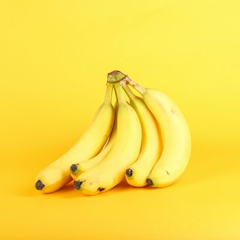

banana audio: 1.08 s, 16 kHz mono; waveform checks passed


apple photograph — source: https://images.unsplash.com/photo-1560806887-1e4cd0b6cbd6?auto=format&fit=crop&w=400&q=80


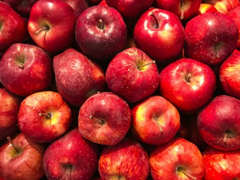

apple audio: 1.01 s, 16 kHz mono; waveform checks passed


In [18]:
import os
import sys
import subprocess
import tempfile
import venv
import wave
from pathlib import Path
import requests
import soundfile as sf
import librosa
from PIL import Image
from IPython.display import Audio

media_dir = Path("l09_multimodal_media")
media_dir.mkdir(exist_ok=True)
REGENERATE_AUDIO = True  # False reuses WAV files from an earlier run.

# Colab-only automatic installation, in an isolated helper environment.
tts_python = os.environ.get("L09_TTS_PYTHON")
if IN_COLAB and not tts_python:
    tts_env = Path(tempfile.gettempdir()) / "l09-tts-helper"
    helper_python = tts_env / ("Scripts/python.exe" if os.name == "nt" else "bin/python")
    if not helper_python.exists():
        venv.EnvBuilder(with_pip=True).create(tts_env)
        subprocess.run([str(helper_python), "-m", "pip", "install", "-q", "gTTS==2.5.4"], check=True)
    tts_python = str(helper_python)
if not tts_python:
    raise RuntimeError("Prepare the local TTS helper and set L09_TTS_PYTHON; see the collapsed setup instructions above.")

image_urls = {
    "banana": "https://images.unsplash.com/photo-1571771894821-ce9b6c11b08e?auto=format&fit=crop&w=400&q=80",
    "apple": "https://images.unsplash.com/photo-1560806887-1e4cd0b6cbd6?auto=format&fit=crop&w=400&q=80",
}

def download_image(url, destination):
    if not destination.exists():
        response = requests.get(url, timeout=30)
        response.raise_for_status()
        destination.write_bytes(response.content)
    with Image.open(destination) as source:
        return source.convert("RGB")

def synthesize_wav(word, destination):
    # Public example word -> Google TTS -> MP3, in the separate helper.
    with tempfile.TemporaryDirectory() as temp_dir:
        mp3_path = Path(temp_dir) / "speech.mp3"
        script = "from gtts import gTTS; import sys; gTTS(text=sys.argv[1], lang='en', slow=False, timeout=30).save(sys.argv[2])"
        subprocess.run([tts_python, "-c", script, word, str(mp3_path)], check=True, timeout=90)
        speech, sample_rate = sf.read(mp3_path, dtype="float32", always_2d=True)
        mono = speech.mean(axis=1)
        mono_16k = librosa.resample(mono, orig_sr=sample_rate, target_sr=16000)
        assert np.isfinite(mono_16k).all()
        sf.write(destination, mono_16k, 16000, subtype="PCM_16")

image_paths, audio_paths = {}, {}
for concept, url in image_urls.items():
    image_paths[concept] = media_dir / f"{concept}.jpg"
    picture = download_image(url, image_paths[concept])
    print(f"{concept} photograph — source: {url}")
    preview = picture.copy()
    preview.thumbnail((240, 240))
    display(preview)

    audio_paths[concept] = media_dir / f"{concept}.wav"
    if REGENERATE_AUDIO or not audio_paths[concept].exists():
        synthesize_wav(concept, audio_paths[concept])
    with wave.open(str(audio_paths[concept])) as wav:
        assert (wav.getframerate(), wav.getnchannels(), wav.getsampwidth()) == (16000, 1, 2)
        samples = np.frombuffer(wav.readframes(wav.getnframes()), dtype="<i2").astype(np.float32) / 32768
    assert np.isfinite(samples).all() and 0 < np.abs(samples).max() <= 1
    print(f"{concept} audio: {samples.size / 16000:.2f} s, 16 kHz mono; waveform checks passed")
    display(Audio(filename=str(audio_paths[concept])))

### Encode First, Then Score

We encode each candidate once. Text candidates use the document prompt; text queries use the search-query prompt. Media use modality dictionaries. All returned vectors are normalized before dot products, making those products cosine similarities.

**Inspect the information flow:** Find the line that passes the WAV file into the model. If the waveform were only loaded or played, would the comparison demonstrate audio encoding?

In [19]:
candidate_names = [
    "banana photograph", "apple photograph",
    "spoken 'banana'", "spoken 'apple'",
    "text: a yellow banana", "text: a red apple",
]
media_inputs = [
    {"image": str(image_paths["banana"])},
    {"image": str(image_paths["apple"])},
    {"audio": str(audio_paths["banana"])},
    {"audio": str(audio_paths["apple"])},
]
# Encode separately to keep the modality-specific calls explicit.
# Fail on numerical preprocessing warnings instead of publishing suspect results.
import warnings
media_vectors = []
for item in media_inputs:
    with warnings.catch_warnings():
        warnings.simplefilter("error", RuntimeWarning)
        vector = multimodal_model.encode(
            item, convert_to_tensor=True, normalize_embeddings=True,
        ).reshape(-1)
    assert torch.isfinite(vector).all()
    media_vectors.append(vector)
text_vectors = multimodal_model.encode(
    ["a yellow banana", "a red apple"], prompt_name="Document",
    convert_to_tensor=True, normalize_embeddings=True,
)
candidate_vectors = torch.stack(media_vectors + list(text_vectors))
search_queries = ["a yellow banana", "a red apple", "a blue car"]
query_vectors = multimodal_model.encode(
    search_queries, prompt_name="SearchQuery",
    convert_to_tensor=True, normalize_embeddings=True,
)
assert candidate_vectors.shape == (6, 768), candidate_vectors.shape
assert torch.isfinite(candidate_vectors).all() and torch.isfinite(query_vectors).all()
assert torch.allclose(candidate_vectors.norm(dim=1), torch.ones(6, device=DEVICE), atol=1e-5)
assert torch.allclose(query_vectors.norm(dim=1), torch.ones(len(search_queries), device=DEVICE), atol=1e-5)
scores = (query_vectors @ candidate_vectors.T).cpu()
assert torch.isfinite(scores).all()
for query, row in zip(search_queries, scores):
    print(f"\nQuery: {query}")
    for index in torch.argsort(row, descending=True).tolist():
        print(f"  {row[index].item(): .4f}  {candidate_names[index]}")
print("Waveform, finite-vector, unit-norm, and finite-score checks passed.")

[transformers] Image decoding with `torchvision` is deprecated and will be removed in future versions .Please install `torchcodec>=0.16.0` instead. 



Query: a yellow banana
   0.9629  text: a yellow banana
   0.8042  spoken 'banana'
   0.7508  text: a red apple
   0.7218  banana photograph
   0.6399  spoken 'apple'
   0.5743  apple photograph

Query: a red apple
   0.9587  text: a red apple
   0.7846  spoken 'apple'
   0.7637  text: a yellow banana
   0.7123  apple photograph
   0.6405  spoken 'banana'
   0.5674  banana photograph

Query: a blue car
   0.7014  text: a red apple
   0.6999  text: a yellow banana
   0.6028  spoken 'apple'
   0.5862  spoken 'banana'
   0.5119  apple photograph
   0.4982  banana photograph
Waveform, finite-vector, unit-norm, and finite-score checks passed.


### Explain What the Rankings Establish

Compare each observed ranking with your prediction. Do image, speech, and text candidates behave alike? Shared space does not imply identical score distributions across modalities.

The query *a blue car* is an **absent-concept control**: there is no car in the candidate collection, but a ranking still returns a winner. Cosine is not a probability, and a top result is not evidence that a relevant item exists. A production system needs evaluation and an appropriate rejection policy.

### Your Turn: Change the Task

1. Add the queries *someone saying banana* and *a photograph of a banana*. Does modality wording change the rankings?
2. Replace one synthesized word with a longer sentence. What information survives in the single vector?
3. Could a spoken fruit name establish what is visible in an unrelated photograph? Explain the difference between shared semantics and verification.

### Connect Back to Matryoshka

The next cell truncates the **same model's** vectors and renormalizes them. Predict whether the top media candidate must remain unchanged. We score only image/audio candidates here so exact text matches do not dominate the inspection.

In [20]:
for dimensions in (768, 512, 256, 128):
    short_queries = F.normalize(query_vectors[:, :dimensions], dim=-1)
    short_media = F.normalize(candidate_vectors[:4, :dimensions], dim=-1)
    short_scores = (short_queries @ short_media.T).cpu()
    print(f"\n{dimensions} dimensions ({dimensions * 4} bytes/vector at float32)")
    for query, row in zip(search_queries, short_scores):
        winner = int(row.argmax())
        print(f"  {query!r}: {candidate_names[winner]} ({row[winner].item():.4f})")


768 dimensions (3072 bytes/vector at float32)
  'a yellow banana': spoken 'banana' (0.8042)
  'a red apple': spoken 'apple' (0.7846)
  'a blue car': spoken 'apple' (0.6028)

512 dimensions (2048 bytes/vector at float32)
  'a yellow banana': spoken 'banana' (0.8074)
  'a red apple': spoken 'apple' (0.7883)
  'a blue car': spoken 'apple' (0.6080)

256 dimensions (1024 bytes/vector at float32)
  'a yellow banana': spoken 'banana' (0.8257)
  'a red apple': spoken 'apple' (0.8087)
  'a blue car': spoken 'apple' (0.6241)

128 dimensions (512 bytes/vector at float32)
  'a yellow banana': spoken 'banana' (0.8621)
  'a red apple': spoken 'apple' (0.8560)
  'a blue car': spoken 'apple' (0.7244)


**Check yourself.**

1. What establishes that the speech is actually encoded?
2. Why can the absent car query still return a fruit?
3. Why can reducing dimension change the winner?

<details>
<summary>Solution: Multimodal alignment and retrieval limits</summary>

1. The WAV file is passed through the audio input of EmbeddingGemma 2. The resulting vector is computed by the model, not constructed from an image vector.

2. Ranking always has a maximum over a nonempty candidate set. A top score is neither a probability nor proof that a relevant candidate exists.

3. Truncation removes components of the learned representation. Even a Matryoshka model trades storage against task-dependent retrieval quality.
</details>

## Summary and Self-Check

| Representation | What produces it? | What did we test? |
| --- | --- | --- |
| Contextual token vector | BERT encoder and surrounding tokens | Dependence on context across layers |
| MLM distribution | Encoder plus vocabulary prediction head | Compatible masked-token completions |
| Text vector | Pooling plus a pretrained encoder | Similarity geometry and retrieval |
| Token-vector set | Encoder without pooling | The MaxSim operation, using unadapted BERT |
| Multimodal vector | EmbeddingGemma 2 with modality encoders | Text queries against real images and synthesized speech |

InfoNCE specifies a learning signal; our matrix experiments compute its loss but do not train an encoder. Matryoshka training supports shorter vectors, with quality that must be checked on the target task.

Before closing the notebook, explain:

1. Why can two occurrences of one token have different vectors while the parameters stay fixed?
2. Why does mean pooling alone not guarantee a useful semantic metric?
3. How can lower temperature decrease one example's loss and increase another's?
4. Why can a reranker fail even if it scores every supplied candidate perfectly?
5. Which outputs are model observations, and which computations used invented inputs?
6. What evidence shows that the final experiment actually uses image and audio encoders?

For cross-modal retrieval, matching vector dimensions are necessary for these dot products; learned compatibility makes them meaningful. Small examples help inspect a mechanism. They do not replace evaluation on realistic data.